In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\AI-MSU")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
daily = pd.read_csv(PROCESSED_DIR / "complete_daily_features.csv", parse_dates=["day"])

print("Dataset shape:", daily.shape)
print("Unique users:", daily["user"].nunique())
print("Date range:", daily["day"].min(), "to", daily["day"].max())
display(daily.head())

Dataset shape: (501000, 14)
Unique users: 1000
Date range: 2010-01-02 00:00:00 to 2011-05-17 00:00:00


,user,day,logon_event_count,logon_after_hours,device_event_count,device_after_hours,file_event_count,file_after_hours,email_event_count,email_after_hours,email_size,email_attachments,http_event_count,http_after_hours
0,AAE0190,2010-01-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,AAE0190,2010-01-03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,AAE0190,2010-01-04,2.0,1.0,0.0,0.0,0.0,0.0,14.0,0.0,441328.0,4.0,143.0,7.0
3,AAE0190,2010-01-05,2.0,1.0,0.0,0.0,0.0,0.0,13.0,0.0,355552.0,2.0,143.0,1.0
4,AAE0190,2010-01-06,2.0,1.0,0.0,0.0,0.0,0.0,14.0,0.0,532647.0,12.0,143.0,3.0


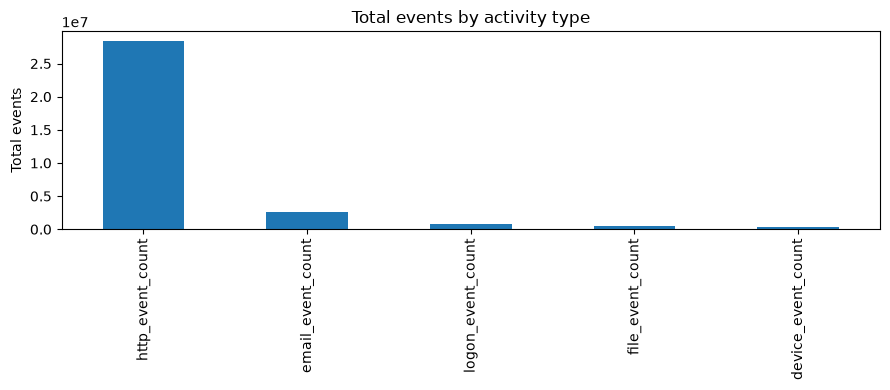

In [2]:
activity_cols = [c for c in daily.columns if c.endswith("_event_count")]
daily[activity_cols].sum().sort_values(ascending=False).plot(kind="bar", figsize=(9, 4))
plt.ylabel("Total events")
plt.title("Total events by activity type")
plt.tight_layout()
plt.show()

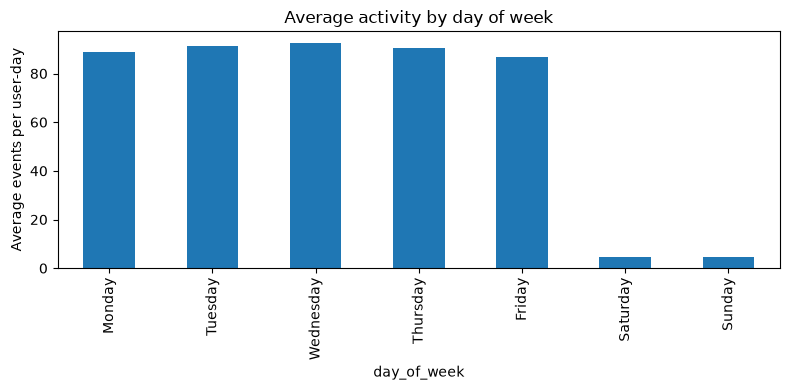

In [3]:
daily["day_of_week"] = daily["day"].dt.day_name()
daily["total_events"] = daily[activity_cols].sum(axis=1)
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily.groupby("day_of_week")["total_events"].mean().reindex(order).plot(kind="bar", figsize=(8, 4))
plt.ylabel("Average events per user-day")
plt.title("Average activity by day of week")
plt.tight_layout()
plt.show()

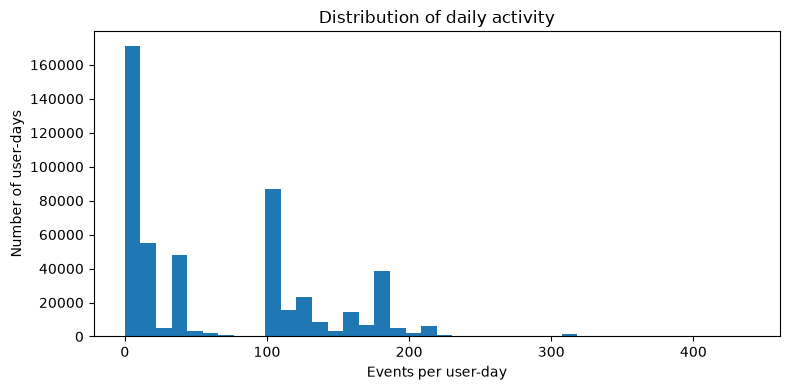

In [4]:
plt.figure(figsize=(8, 4))
plt.hist(daily["total_events"], bins=40)
plt.xlabel("Events per user-day")
plt.ylabel("Number of user-days")
plt.title("Distribution of daily activity")
plt.tight_layout()
plt.show()